In [ ]:
import random
from typing import List, Tuple

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
)

import torch
import torch.nn as nn
import torch.optim as optim
import torchmetrics
from torch.utils.data import (
    Dataset,
    DataLoader,
    RandomSampler,
    SequentialSampler,
    WeightedRandomSampler,
)
from torch.nn.utils.rnn import pad_sequence

import transformers
from transformers import (
    AutoTokenizer,
    AutoConfig,
    AutoModel,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    pipeline,
)

from tqdm.notebook import tqdm

import warnings

warnings.filterwarnings(action="ignore")

In [2]:
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

In [3]:
set_seed()

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Используемое устройство: {device}")

Используемое устройство: cuda


Загрузим датасет с отзывами. Возьмем только два столбца - `text`, `label`.


In [ ]:
file_path = "/kaggle/input/food-reviews-data/food_reviews.csv"
df = pd.read_csv(file_path, sep=",", usecols=[3, 4], header=0, names=["label", "text"])

In [9]:
df.head()

,label,text
0,positive,I have bought several of the Vitality canned d...
1,negative,Product arrived labeled as Jumbo Salted Peanut...
2,neutral,This is a confection that has been around a fe...
3,neutral,If you are looking for the secret ingredient i...
4,positive,Great taffy at a great price. There was a wid...


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15691 entries, 0 to 15690
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   15691 non-null  object
 1   text    15691 non-null  object
dtypes: object(2)
memory usage: 245.3+ KB


Проверим на наличие дубликатов. Если есть - удалим.


In [12]:
print(df.duplicated().sum())

598


In [13]:
df = df.drop_duplicates(keep="first", ignore_index=True)

Создадим два словаря - `label2id` и `id2label`


In [14]:
label2id = {label: i for i, label in enumerate(df["label"].unique())}
id2label = {i: label for label, i in label2id.items()}

df["label"] = df["label"].map(label2id)

In [15]:
print(label2id)
print(id2label)

{'positive': 0, 'negative': 1, 'neutral': 2}
{0: 'positive', 1: 'negative', 2: 'neutral'}


In [90]:
print("Распределение отзывов\n")
print(df["label"].value_counts(normalize=True))

Распределение отзывов

label
0    0.630557
2    0.277281
1    0.092162
Name: proportion, dtype: float64


In [17]:
def get_text_length(df: pd.DataFrame):
    """Выводит статистику по длине текстов"""
    lengths = []
    for text in df.text:
        tokens = text.split()
        lengths.append(len(tokens))
    lengths = np.array(lengths)
    print(f"Средняя длина: {np.mean(lengths):.1f}")
    print(f"Максимальная длина: {np.max(lengths)}")
    print(f"Минимальная длина: {np.min(lengths)}")
    print(f"95-й перцентиль: {np.percentile(lengths, 95)}")
    return lengths

Посмотрим на распределение длин текстов в нашем датасете. Используем 95-й перцентиль для ограничения при кодировании.


In [18]:
text_lengths = get_text_length(df)

Средняя длина: 78.3
Максимальная длина: 1751
Минимальная длина: 6
95-й перцентиль: 209.0


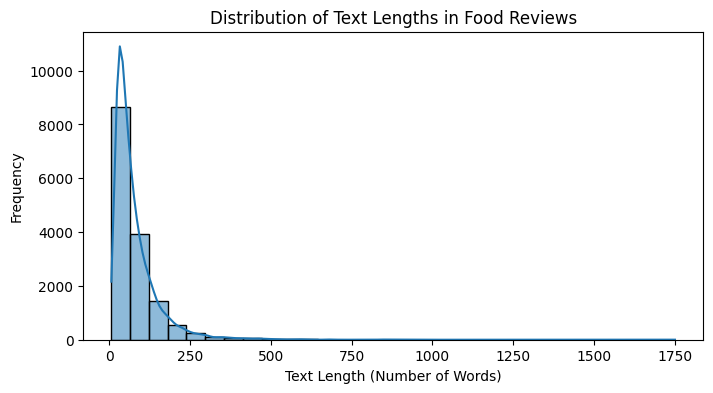

In [19]:
plt.figure(figsize=(8, 4))
sns.histplot(text_lengths, bins=30, kde=True)
plt.xlabel("Text Length (Number of Words)")
plt.ylabel("Frequency")
plt.title("Distribution of Text Lengths in Food Reviews")
plt.show()

In [20]:
model_checkpoint = "bert-base-uncased"

In [21]:
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [22]:
def split_data(df, test_size=0.2, val_size=0.1, random_state=42):
    train_df, test_df = train_test_split(
        df, test_size=test_size, random_state=random_state, stratify=df["label"]
    )
    train_df, val_df = train_test_split(
        train_df,
        test_size=val_size,
        random_state=random_state,
        stratify=train_df["label"],
    )
    return (
        train_df.reset_index(drop=True),
        val_df.reset_index(drop=True),
        test_df.reset_index(drop=True),
    )

In [23]:
train_df, val_df, test_df = split_data(df)

In [24]:
print(f"Тренировочный набор: {len(train_df)} примеров")
print(f"Валидационный набор: {len(val_df)} примеров")
print(f"Тестовый набор: {len(test_df)} примеров")

Тренировочный набор: 10866 примеров
Валидационный набор: 1208 примеров
Тестовый набор: 3019 примеров


In [25]:
class TextDataset(Dataset):
    """
    Args:
        texts: список или Series с текстами
        labels: список или Series с метками (для инференса может быть None)
        tokenizer: BERT токенизатор
        max_length: максимальная длина последовательности
        for_inference: флаг для инференса (без labels)
    """

    def __init__(self, texts, labels, tokenizer, max_len=128, for_inference=False):
        self.texts = (
            texts.reset_index(drop=True) if isinstance(texts, pd.Series) else texts
        )
        self.labels = (
            labels.reset_index(drop=True)
            if labels is not None and isinstance(labels, pd.Series)
            else labels
        )
        self.tokenizer = tokenizer
        self.max_len = max_len
        self.for_inference = for_inference

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, item):
        text = str(self.texts[item])
        label = self.labels[item]

        encoding = self.tokenizer.encode_plus(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            truncation=True,
            return_attention_mask=True,
            return_tensors="pt",
        )

        output = {
            "input_ids": encoding["input_ids"].flatten(),
            "attention_mask": encoding["attention_mask"].flatten(),
        }

        if not self.for_inference and self.labels is not None:
            output["labels"] = torch.tensor(label, dtype=torch.long)

        return output

    def get_class_weight(self):
        if self.labels is None:
            return None
        classes = np.unique(self.labels)
        class_weights = compute_class_weight(
            class_weight="balanced", classes=classes, y=self.labels
        )
        return torch.tensor(class_weights, dtype=torch.float)

In [26]:
train_dataset = TextDataset(
    texts=train_df["text"].tolist(),
    labels=train_df["label"].tolist(),
    tokenizer=tokenizer,
    max_len=256,
    for_inference=False,
)

val_dataset = TextDataset(
    texts=val_df["text"].tolist(),
    labels=val_df["label"].tolist(),
    tokenizer=tokenizer,
    max_len=256,
    for_inference=False,
)

test_dataset = TextDataset(
    texts=test_df["text"].tolist(),
    labels=test_df["label"].tolist(),
    tokenizer=tokenizer,
    max_len=256,
    for_inference=False,
)

In [27]:
print("Пример элемента датасета:")
sample = train_dataset[0]
print(f"Input IDs shape: {sample['input_ids'].shape}")
print(f"Attention mask shape: {sample['attention_mask'].shape}")
print(f"Label: {sample.get('labels', 'No label for inference')}")


Пример элемента датасета:
Input IDs shape: torch.Size([27])
Attention mask shape: torch.Size([27])
Label: 1


In [28]:
def collate_fn(batch):
    input_ids = [item["input_ids"] for item in batch]
    attention_mask = [item["attention_mask"] for item in batch]
    labels = [item["labels"] for item in batch]

    input_ids = pad_sequence(input_ids, batch_first=True, padding_value=0)
    attention_mask = pad_sequence(attention_mask, batch_first=True, padding_value=0)
    labels = torch.tensor(labels, dtype=torch.long)

    return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}

In [29]:
def create_dataloaders(
    train_dataset,
    val_dataset,
    test_dataset,
    batch_size=16,
    use_weighted_sampler=False,
):
    """
    Создает DataLoader'ы для всех наборов данных

    Args:
        train_dataset: тренировочный датасет
        val_dataset: валидационный датасет
        test_dataset: тестовый датасет
        batch_size: размер батча
        use_weighted_sampler: использовать ли WeightedRandomSampler для несбалансированных данных
    """
    if use_weighted_sampler:
        class_weights = train_dataset.get_class_weight()
        sample_weights = [class_weights[label] for label in train_dataset.labels]
        sampler = WeightedRandomSampler(
            weights=sample_weights,
            num_samples=len(sample_weights),
            replacement=True,
        )
        train_loader = DataLoader(
            train_dataset,
            sampler=sampler,
            batch_size=batch_size,
            collate_fn=collate_fn,
            pin_memory=True if torch.cuda.is_available() else False,
        )
    else:
        train_loader = DataLoader(
            train_dataset,
            sampler=RandomSampler(train_dataset),
            batch_size=batch_size,
            collate_fn=collate_fn,
            pin_memory=True if torch.cuda.is_available() else False,
        )

    val_loader = DataLoader(
        val_dataset,
        sampler=SequentialSampler(val_dataset),
        batch_size=batch_size,
        collate_fn=collate_fn,
        pin_memory=True if torch.cuda.is_available() else False,
    )

    test_loader = DataLoader(
        test_dataset,
        sampler=SequentialSampler(test_dataset),
        batch_size=batch_size,
        collate_fn=collate_fn,
        pin_memory=True if torch.cuda.is_available() else False,
    )

    return train_loader, val_loader, test_loader

In [30]:
BATCH_SIZE = 32

In [91]:
train_loader, val_loader, test_loader = create_dataloaders(
    train_dataset,
    val_dataset,
    test_dataset,
    batch_size=BATCH_SIZE,
    use_weighted_sampler=True,
)

In [97]:
print("Информация о даталоадерах:")
print(f"Количество батчей в train_loader: {len(train_loader)}")
print(f"Количество батчей в val_loader: {len(val_loader)}")
print(f"Количество батчей в test_loader: {len(test_loader)}")

Информация о даталоадерах:
Количество батчей в train_loader: 340
Количество батчей в val_loader: 38
Количество батчей в test_loader: 95


In [96]:
print("Первый батч из train_loader:")
for batch in train_loader:
    print(f"Batch keys: {batch.keys()}")
    print(f"Input IDs shape: {batch['input_ids'].shape}")
    print(f"Attention mask shape: {batch['attention_mask'].shape}")
    print(f"Labels shape: {batch['labels'].shape}")
    print(f"Labels values: {batch['labels']}")
    break

Первый батч из train_loader:
Batch keys: dict_keys(['input_ids', 'attention_mask', 'labels'])
Input IDs shape: torch.Size([32, 256])
Attention mask shape: torch.Size([32, 256])
Labels shape: torch.Size([32])
Labels values: tensor([2, 1, 1, 2, 0, 1, 2, 2, 0, 1, 2, 0, 2, 1, 0, 0, 2, 1, 2, 2, 2, 1, 1, 0,
        1, 2, 0, 0, 0, 2, 0, 0])


In [95]:
print("Просмотр нескольких батчей из train_loader:")
for i, batch in enumerate(train_loader):
    if i >= 2:
        break
    print(f"Батч {i}:")
    print(f"  Размер батча: {len(batch['input_ids'])}")
    print(
        f"  Пример текста (декодированный): {tokenizer.decode(batch['input_ids'][0][:10])}..."
    )
    print()

Просмотр нескольких батчей из train_loader:
Батч 0:
  Размер батча: 32
  Пример текста (декодированный):  likeiumaf housing miss TV Clubaf Electronicsfore...

Батч 1:
  Размер батча: 32
  Пример текста (декодированный):  like packaging hundreds star create showing innings asking signs fifth...



Определим несколько функция для тренировки, валидации и тестирования!


In [64]:
def evaluate(model, val_loader, loss_fn, metric, trainer=False):
    model.eval()
    metric.reset()
    total_val_loss = 0
    with torch.no_grad():
        test_loop = tqdm(val_loader, desc="Evaluating", leave=False)
        for batch in test_loop:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            logits = outputs.logits if trainer else outputs
            loss = loss_fn(logits, labels)

            total_val_loss += loss.item()
            metric.update(logits, labels)
            test_loop.set_postfix(
                {"loss": loss.item(), "accuracy": metric.compute().item()}
            )

    avg_val_loss = total_val_loss / len(val_loader)
    val_accuracy = metric.compute().item()
    return avg_val_loss, val_accuracy

In [ ]:
def train(
    model,
    optimizer,
    loss_fn,
    metric,
    train_loader,
    val_loader,
    device,
    epochs,
    patience=2,
    clip_value=1.0,
    factor=0.5,
    trainer=False,
):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=factor, patience=patience
    )
    history = {
        "train_losses": [],
        "test_losses": [],
        "train_metrics": [],
        "valid_metrics": [],
    }
    for epoch in range(epochs):
        model.train()
        metric.reset()
        total_loss = 0

        train_loop = tqdm(train_loader, desc=f"Training Epoch {epoch + 1}")
        for batch in train_loop:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            optimizer.zero_grad()
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            logits = outputs.logits if trainer else outputs
            loss = outputs.loss if hasattr(logits, "loss") else loss_fn(logits, labels)
            total_loss += loss.item()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip_value)
            optimizer.step()
            metric.update(logits, labels)
            train_metic = metric.compute().item()
            train_loop.set_postfix({"loss": loss.item(), "accuracy": train_metic})

        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(train_metic)
        avg_val_loss, val_accuracy = evaluate(model, val_loader, loss_fn, metric)
        history["valid_metrics"].append(val_accuracy)
        history["test_losses"].append(avg_val_loss)
        scheduler.step(val_accuracy)

        print(
            f"\rEpoch {epoch + 1}/{epochs}, "
            f"train loss: {history['train_losses'][-1]:.4f}, "
            f"test loss: {history['test_losses'][-1]:.4f}, "
            f"train metric: {history['train_metrics'][-1]:.2%}, "
            f"valid metric: {history['valid_metrics'][-1]:.2%}"
        )
    return history

In [67]:
def predict_sentiment(text, model, tokenizer, id2label, trainer=False):
    """Функция для предсказания тональности одного текста"""
    encoding = tokenizer.encode_plus(
        text,
        add_special_tokens=True,
        max_length=256,
        padding="max_length",
        truncation=True,
        return_attention_mask=True,
        return_tensors="pt",
    )

    model.eval()

    with torch.no_grad():
        input_ids = encoding["input_ids"].to(device)
        attention_mask = encoding["attention_mask"].to(device)

        outputs = model(input_ids, attention_mask=attention_mask)
        logits = outputs.logits if trainer else outputs
        predictions = torch.argmax(logits, dim=1)

        probabilities = torch.nn.functional.softmax(logits, dim=1)

        predicted_label = id2label[predictions.item()]
        confidence = probabilities[0][predictions.item()].item()

    return predicted_label, confidence

In [51]:
class BertSentimentClassifier(nn.Module):
    def __init__(self, model_checkpoint, num_labels):
        super(BertSentimentClassifier, self).__init__()
        self.bert = AutoModel.from_pretrained(model_checkpoint)
        self.dropout = nn.Dropout(p=0.1)
        self.classifier = nn.Linear(self.bert.config.hidden_size, num_labels)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
        )
        pooled_output = outputs.pooler_output
        logits = self.classifier(self.dropout(pooled_output))
        return logits

Для бейзлайна будем брать только `pooler_output` из `Bert`. Все его веса заморозим.


In [46]:
model_bert_cls = BertSentimentClassifier(model_checkpoint, num_labels=len(label2id))
model_bert_cls.bert.requires_grad_(False)
model_bert_cls = model_bert_cls.to(device)

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

In [47]:
epochs = 7
class_weights = train_dataset.get_class_weight().to(device)
loss_fn = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.AdamW(model_bert_cls.parameters(), lr=2e-5, eps=1e-8)
metric = torchmetrics.Accuracy(task="multiclass", num_classes=len(label2id)).to(device)

history = train(
    model_bert_cls,
    optimizer,
    loss_fn,
    metric,
    train_loader,
    val_loader,
    device,
    epochs,
)

Training Epoch 1:   0%|          | 0/340 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/38 [00:00<?, ?it/s]

Epoch 1/7,                      train loss: 0.8060, test loss: 1.2448, train metric: 33.40%, valid metric: 9.35%


Training Epoch 2:   0%|          | 0/340 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/38 [00:00<?, ?it/s]

Epoch 2/7,                      train loss: 0.7022, test loss: 1.0607, train metric: 37.19%, valid metric: 24.67%


... (11 outputs left out)

Epoch 6/7,                      train loss: 0.5618, test loss: 0.8851, train metric: 58.56%, valid metric: 47.93%


Training Epoch 7:   0%|          | 0/340 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/38 [00:00<?, ?it/s]

Epoch 7/7,                      train loss: 0.5546, test loss: 0.8538, train metric: 59.76%, valid metric: 52.24%


In [52]:
def plot_stats(history):
    epochs = range(1, len(history["train_losses"]) + 1)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_losses"], label="Train Loss")
    plt.plot(epochs, history["test_losses"], label="Validation Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.title("Training and Validation Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["train_metrics"], label="Train Accuracy")
    plt.plot(epochs, history["valid_metrics"], label="Validation Accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.title("Training and Validation Accuracy")
    plt.legend()

    plt.tight_layout()
    plt.show()

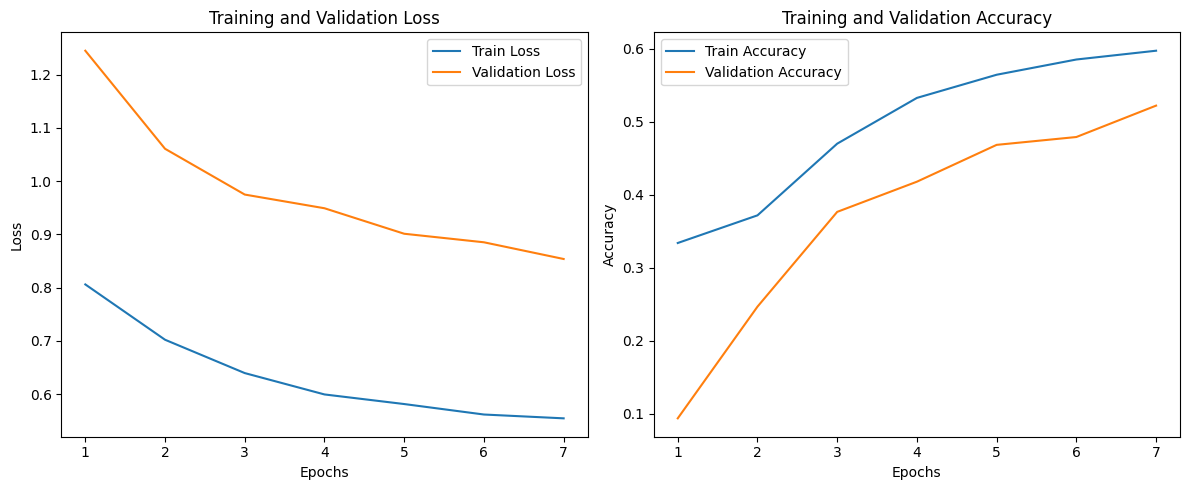

In [49]:
plot_stats(history)

In [ ]:
test_loss, test_accuracy = evaluate(model_bert_cls, test_loader, loss_fn, metric)

print(f"\nТестовая потеря: {test_loss:.4f}")
print(f"Тестовая точность: {test_accuracy:.2%}")

Evaluating:   0%|          | 0/95 [00:00<?, ?it/s]


Тестовая потеря: 0.8569
Тестовая точность: 51.28%


### Вывод по бейзлайн-модели (замороженный BERT + `pooler_output`)

Бейзлайн-подход — использование **замороженного BERT** и обучение только поверх его `pooler_output` — показал **ограниченную эффективность**:

- Несмотря на постепенное улучшение валидационной метрики (с 9.35% до 52.24% за 7 эпох),
- **Финальная точность (~52%)** - довольно плохо, только 5 из 10 "отгадывает",
- Наблюдается **сильный разрыв между train и valid метриками**, что указывает на неспособность замороженного признакового пространства адекватно выразить специфику нашей задачи.

Это подтверждает: для достижения высокого качества на задаче сентимент-анализа **необходимо дообучать сам BERT**, а не использовать его как фиксированный экстрактор признаков.


In [55]:
model_bert = BertSentimentClassifier(model_checkpoint, num_labels=len(label2id))
model_bert = model_bert.to(device)

epochs = 7
class_weights = train_dataset.get_class_weight().to(device)
loss_fn = nn.CrossEntropyLoss(weight=class_weights)
optimizer = optim.AdamW(model_bert.parameters(), lr=2e-5, eps=1e-8)
metric = torchmetrics.Accuracy(task="multiclass", num_classes=len(label2id)).to(device)

history = train(
    model_bert,
    optimizer,
    loss_fn,
    metric,
    train_loader,
    val_loader,
    device,
    epochs,
)

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Training Epoch 1:   0%|          | 0/340 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/38 [00:00<?, ?it/s]

Epoch 1/7,                      train loss: 0.4393, test loss: 0.6373, train metric: 68.26%, valid metric: 75.25%


Training Epoch 2:   0%|          | 0/340 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/38 [00:00<?, ?it/s]

... (12 outputs left out)

Epoch 6/7,                      train loss: 0.0536, test loss: 1.1467, train metric: 96.46%, valid metric: 77.98%


Training Epoch 7:   0%|          | 0/340 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/38 [00:00<?, ?it/s]

Epoch 7/7,                      train loss: 0.0407, test loss: 1.5113, train metric: 97.66%, valid metric: 78.39%


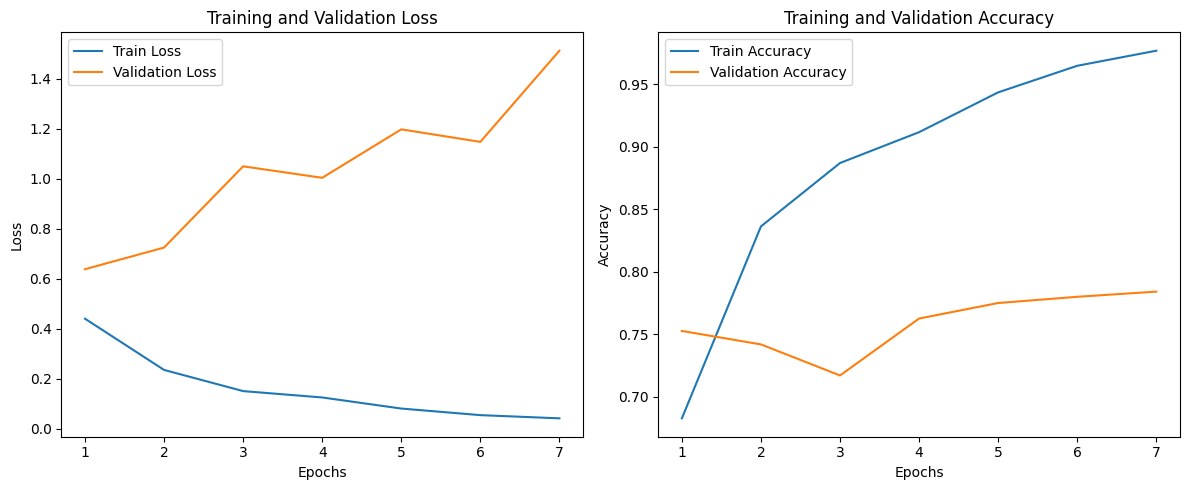

In [56]:
plot_stats(history)

In [ ]:
test_loss, test_accuracy = evaluate(model_bert, test_loader, loss_fn, metric)

print(f"\nТестовая потеря: {test_loss:.4f}")
print(f"Тестовая точность: {test_accuracy:.2%}")

Evaluating:   0%|          | 0/95 [00:00<?, ?it/s]


Тестовая потеря: 1.6185
Тестовая точность: 79.43%


### Анализ модели с полным fine-tuning'ом BERT

Полный дообученный BERT демонстрирует **значительно лучшее качество** по сравнению с бейзлайном: финальная валидационная точность достигает **78.39%**, что на ~26 процентных пунктов выше, чем у замороженной версии.

Однако уже со **2-й эпохи** наблюдается тревожный признак:

- **Тренировочная точность продолжает уверенно расти** (от 68% до 97%),
- В то время как **валидационная метрика стагнирует** (пик — 77.48% на 5-й эпохе) и даже **начинает снижаться** на последней эпохе (78.39% → но при росте валидационного лосса до 1.51).

Это классический признак **переобучения**: модель начинает запоминать обучающие примеры вместо обобщения.


In [72]:
test_texts = [
    "This product is amazing! I love it so much.",
    "Worst experience ever, never buying again.",
    "It's just average, nothing special.",
]

print("\nПримеры предсказаний:")
for text in test_texts:
    label, confidence = predict_sentiment(text, model_bert, tokenizer, id2label)
    print(f"Текст: {text[:50]}...")
    print(f"  Предсказание: {label} (уверенность: {confidence:.2%})")
    print("-" * 50)


Примеры предсказаний:
Текст: This product is amazing! I love it so much....
  Предсказание: positive (уверенность: 99.34%)
--------------------------------------------------
Текст: Worst experience ever, never buying again....
  Предсказание: negative (уверенность: 99.75%)
--------------------------------------------------
Текст: It's just average, nothing special....
  Предсказание: neutral (уверенность: 99.57%)
--------------------------------------------------


## Вариант 2: Дообучение с использованием Trainer API

В этом подходе мы используем готовую модель `BertForSequenceClassification` и дообучаем её на нашей задаче с помощью высокоуровневого `Trainer` API от Hugging Face. В отличие от кастомной архитектуры, здесь мы работаем с полностью предобученным BERT-энкодером и случайно инициализированной головой классификации, которую модель адаптирует под наши данные в процессе fine-tuning.


Для загрузки и публикации моделей в Hugging Face Hub необходимо пройти аутентификацию.  
Выполните код ниже и **вставьте свой токен** (его можно получить в [настройках аккаунта Hugging Face](https://huggingface.co/settings/tokens)).


In [ ]:
from huggingface_hub import notebook_login

notebook_login()

In [39]:
model = AutoModelForSequenceClassification.from_pretrained(
    model_checkpoint,
    num_labels=len(label2id),
)

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
def compute_metrics(p):
    predictions, labels = p
    predictions = np.argmax(predictions, axis=1)

    accuracy = accuracy_score(labels, predictions)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average="weighted"
    )

    cm = confusion_matrix(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "confusion_matrix": cm.tolist(),
    }

In [ ]:
training_args = TrainingArguments(
    output_dir="bert-finetuned-sentiment",
    num_train_epochs=5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    warmup_steps=100,
    learning_rate=2e-5,
    weight_decay=0.01,
    logging_dir="./logs",
    logging_steps=10,
    eval_strategy="epoch",
    save_strategy="epoch",
    report_to="none",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,
    fp16=torch.cuda.is_available(),
    push_to_hub=True,
)

In [50]:
data_collator = DataCollatorWithPadding(tokenizer)

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics,
    processing_class=tokenizer,
    data_collator=data_collator,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

In [52]:
print("Начинаем обучение модели...")
trainer.train()

Начинаем обучение модели...


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Confusion Matrix
1,0.489400,0.512131,0.793874,0.789588,0.793874,0.779172,"[[712, 8, 42], [10, 92, 9], [143, 37, 155]]"
2,0.357700,0.507348,0.794702,0.785432,0.794702,0.782222,"[[718, 6, 38], [10, 71, 30], [147, 17, 171]]"
3,0.235300,0.549049,0.799669,0.794254,0.799669,0.795457,"[[682, 10, 70], [6, 86, 19], [113, 24, 198]]"
4,0.167000,0.628426,0.798013,0.791160,0.798013,0.792421,"[[695, 5, 62], [8, 69, 34], [119, 16, 200]]"
5,0.129700,0.698386,0.804636,0.797605,0.804636,0.799162,"[[697, 6, 59], [6, 76, 29], [117, 19, 199]]"


TrainOutput(global_step=1700, training_loss=0.33902603282647975, metrics={'train_runtime': 1461.4263, 'train_samples_per_second': 37.176, 'train_steps_per_second': 1.163, 'total_flos': 7036268434332732.0, 'train_loss': 0.33902603282647975, 'epoch': 5.0})

In [54]:
test_results = trainer.evaluate(test_dataset)

In [ ]:
cm = np.array(test_results["eval_confusion_matrix"])
labels = ["positive", "negative", "neutral"]

print(f"\nТестовая точность: {test_results['eval_accuracy']:.4f}")
print(f"Тестовый F1-score: {test_results['eval_f1']:.4f}")
print("\nМатрица ошибок на тестовом наборе:")
print(pd.DataFrame(cm, index=labels, columns=labels))


Тестовая точность: 0.8085
Тестовый F1-score: 0.8056

Матрица ошибок на тестовом наборе:
          positive  negative  neutral
positive      1731        10      163
negative        22       180       76
neutral        227        80      530


По результатам обучения с использованием **Trainer API** мы наблюдаем сопоставимое качество модели:

- **Тестовая точность (Accuracy):** 0.8085


In [ ]:
def save_model(model, tokenizer, path="./bert-sentiment-fine-tuned-model"):
    """
    Сохраняет модель и токенизатор
    """
    model.save_model(path)
    tokenizer.save_pretrained(path)
    print(f"Модель сохранена в {path}")


def load_model(path="./bert-sentiment-fine-tuned-model", device="cpu"):
    """
    Загружает модель и токенизатор
    """
    model = AutoModelForSequenceClassification.from_pretrained(
        path, num_labels=len(label2id)
    )
    tokenizer = AutoTokenizer.from_pretrained(path)
    model.to(device)
    return model, tokenizer

In [71]:
save_model(trainer, tokenizer)

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

No files have been modified since last commit. Skipping to prevent empty commit.


Модель сохранена в ./bert-sentiment-fine-tuned-model


In [ ]:
model, tokenizer = load_model(
    "/kaggle/working/bert-sentiment-fine-tuned-model", device=device
)

In [ ]:
test_texts = [
    "This product is amazing! I love it so much.",
    "Worst experience ever, never buying again.",
    "It's just average, nothing special.",
]

print("\nПримеры предсказаний:")
for text in test_texts:
    label, confidence = predict_sentiment(
        text, model, tokenizer, id2label, trainer=True
    )
    print(f"Текст: {text[:50]}...")
    print(f"  Предсказание: {label} (уверенность: {confidence:.2%})")
    print("-" * 50)


Примеры предсказаний:
Текст: This product is amazing! I love it so much....
  Предсказание: positive (уверенность: 99.47%)
--------------------------------------------------
Текст: Worst experience ever, never buying again....
  Предсказание: negative (уверенность: 98.01%)
--------------------------------------------------
Текст: It's just average, nothing special....
  Предсказание: neutral (уверенность: 86.33%)
--------------------------------------------------


## Оптимизация гиперпараметров

А теперь давайте выведем качество модели на новый уровень!  
Несмотря на уже неплохие результаты, мы можем попробовать **автоматически подобрать оптимальные гиперпараметры** — такие как learning rate, размер батча, количество эпох и другие.

Для этого воспользуемся интеграцией **Hugging Face Transformers с Optuna** — мощной библиотекой для байесовской оптимизации.  
Запустим поиск по пространству гиперпараметров и найдём комбинацию, которая максимизирует метрику качества (например, accuracy или F1-score) на валидационной выборке.


In [75]:
def model_init():
    return AutoModelForSequenceClassification.from_pretrained(
        "/kaggle/working/bert-sentiment-fine-tuned-model", num_labels=len(label2id)
    )

In [77]:
trainer = Trainer(
    model_init=model_init,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

In [80]:
def compute_objective(metrics):
    return metrics["eval_accuracy"]

К сожалению, у меня не хватило памяти :(

P.S. В целом можно заметить, что мы врядли сможем добиться значимо большего accuracy. Поэтому предлагаю остановиться на том, что есть.


In [ ]:
best_run = trainer.hyperparameter_search(
    n_trials=10, direction="maximize", compute_objective=compute_objective
)

[I 2026-01-17 18:11:13,245] A new study created in memory with name: no-name-540ecdd4-7ab9-41b2-bae4-2117839c25ee


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Confusion Matrix
1,0.371600,0.634596,0.756623,0.772204,0.756623,0.761922,"[[619, 6, 137], [2, 69, 40], [89, 20, 226]]"
2,0.201600,0.676177,0.783940,0.773911,0.783940,0.775192,"[[694, 7, 61], [5, 80, 26], [135, 27, 173]]"
3,0.133100,0.801305,0.788079,0.793052,0.788079,0.788928,"[[660, 3, 99], [4, 64, 43], [90, 17, 228]]"
4,0.033500,1.084991,0.801325,0.798888,0.801325,0.798845,"[[686, 1, 75], [4, 65, 42], [99, 19, 217]]"


[I 2026-01-17 18:30:19,855] Trial 0 finished with value: 0.8013245033112583 and parameters: {'learning_rate': 9.863760261819112e-05, 'num_train_epochs': 4, 'seed': 5, 'per_device_train_batch_size': 32}. Best is trial 0 with value: 0.8013245033112583.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Confusion Matrix
1,0.471900,0.646650,0.747517,0.750000,0.747517,0.742227,"[[660, 1, 101], [13, 43, 55], [124, 11, 200]]"
2,0.427600,0.626968,0.767384,0.765635,0.767384,0.765664,"[[656, 17, 89], [2, 82, 27], [113, 33, 189]]"
3,0.237300,0.915338,0.784768,0.778901,0.784768,0.780371,"[[683, 4, 75], [4, 69, 38], [122, 17, 196]]"
4,0.067900,1.178498,0.783940,0.781731,0.783940,0.782111,"[[672, 4, 86], [3, 68, 40], [109, 19, 207]]"


[I 2026-01-17 18:56:55,107] Trial 1 finished with value: 0.7839403973509934 and parameters: {'learning_rate': 8.948381778002342e-05, 'num_train_epochs': 4, 'seed': 13, 'per_device_train_batch_size': 4}. Best is trial 0 with value: 0.8013245033112583.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Confusion Matrix
1,0.341000,1.111349,0.788079,0.783683,0.788079,0.785263,"[[676, 8, 78], [7, 70, 34], [110, 19, 206]]"
2,0.132000,1.231750,0.793874,0.788767,0.793874,0.788437,"[[693, 3, 66], [7, 64, 40], [121, 12, 202]]"
3,0.003600,1.307706,0.791391,0.786310,0.791391,0.788249,"[[678, 7, 77], [6, 77, 28], [110, 24, 201]]"
4,0.074600,1.357535,0.798013,0.792547,0.798013,0.794251,"[[686, 5, 71], [7, 73, 31], [111, 19, 205]]"


... (2 outputs left out)

[I 2026-01-17 19:40:26,268] Trial 3 finished with value: 0.8029801324503312 and parameters: {'learning_rate': 1.195159064718899e-06, 'num_train_epochs': 3, 'seed': 40, 'per_device_train_batch_size': 32}. Best is trial 3 with value: 0.8029801324503312.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Confusion Matrix
1,0.109900,0.722528,0.799669,0.795413,0.799669,0.796783,"[[683, 5, 74], [6, 73, 32], [107, 18, 210]]"


[W 2026-01-17 19:44:54,876] Trial 4 failed with parameters: {'learning_rate': 1.0166494706064019e-05, 'num_train_epochs': 3, 'seed': 24, 'per_device_train_batch_size': 64} because of the following error: SafetensorError('Error while serializing: I/O error: No space left on device (os error 28)').
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/optuna/study/_optimize.py", line 205, in _run_trial
    value_or_values = func(trial)
                      ^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/transformers/integrations/integration_utils.py", line 277, in _objective
    trainer.train(resume_from_checkpoint=checkpoint, trial=trial)
  File "/usr/local/lib/python3.12/dist-packages/transformers/trainer.py", line 2316, in train
    return inner_training_loop(
           ^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/transformers/trainer.py", line 2790, in _inner_training_loop
    self._maybe_log_save_evaluate(
  File "/u

SafetensorError: Error while serializing: I/O error: No space left on device (os error 28)

In [92]:
!rm -rf /kaggle/working/bert-finetuned-sentiment

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


In [ ]:
best_run

In [ ]:
for n, v in best_run.hyperparameters.items():
    setattr(trainer.args, n, v)

trainer.train()

### Финальная проверка: готовая модель из Hugging Face Hub

Напоследок протестируем качество **специализированной предобученной модели для анализа сентимента**, доступной в Hugging Face Hub:


In [ ]:
model_path = "cardiffnlp/twitter-roberta-base-sentiment-latest"
sentiment_task = pipeline(
    "sentiment-analysis",
    model=model_path,
    tokenizer=model_path,
    truncation=True,
    max_length=256,
)

Some weights of the model checkpoint at cardiffnlp/twitter-roberta-base-sentiment-latest were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Device set to use cuda:0


In [ ]:
texts = [text for text in df["text"]]
true_labels = [label for label in df["label"]]

In [109]:
print(texts[:10])
print(labels[:10])

['I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more like a stew than a processed meat and it smells better. My Labrador is finicky and she appreciates this product better than  most.', 'Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if the vendor intended to represent the product as Jumbo.', 'This is a confection that has been around a few centuries.  It is a light, pillowy citrus gelatin with nuts - in this case Filberts. And it is cut into tiny squares and then liberally coated with powdered sugar.  And it is a tiny mouthful of heaven.  Not too chewy, and very flavorful.  I highly recommend this yummy treat.  If you are familiar with the story of C.S. Lewis The Lion, The Witch, and The Wardrobe - this is the treat that seduces Edmund into selling out his Brother and Sisters to the Witch.', 'If you are looking for the se

In [ ]:
def evaluate_with_pipeline(classifier, texts, label2id=None):
    predictions = classifier(texts)
    pred_labels = []
    for pred in predictions:
        label = pred["label"]
        if label2id:
            pred_labels.append(label2id[label])
        else:
            pred_labels.append(label)

    return accuracy_score(true_labels, pred_labels)

In [122]:
accuracy = evaluate_with_pipeline(sentiment_task, texts, label2id)
print(f"Точность на всем датасете равна - {accuracy}")

Точность на всем датасете равна - 0.6910488305837144


Видим, что предобученная модель на других данных дает результат хуже приблизительно на 10%.
